In [2]:
!pip install -q sacrebleu sentencepiece gradio
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [3]:
HIGH_LANG = "arb_Arab"
HIGH_NAME = "Arabic"
LOW_LANG = "urd_Arab"
LOW_NAME = "Urdu"
N_SENTENCES = 100
LANGS = {HIGH_NAME: HIGH_LANG, LOW_NAME: LOW_LANG}
print(LANGS)

{'Arabic': 'arb_Arab', 'Urdu': 'urd_Arab'}


In [4]:
from huggingface_hub import login
from google.colab import userdata
login(token=userdata.get("HF_TOKEN"))
print("Logged in")

Logged in


In [5]:
import pandas as pd
from datasets import load_dataset

eng = load_dataset("openlanguagedata/flores_plus", "eng_Latn", split="devtest").to_pandas()
data = pd.DataFrame({"id": eng["id"], "eng_Latn": eng["text"]})

for name in LANGS:
    code = LANGS[name]
    other = load_dataset("openlanguagedata/flores_plus", code, split="devtest").to_pandas()
    other = pd.DataFrame({"id": other["id"], code: other["text"]})
    data = data.merge(other, on="id")

print("Sentences in all languages:", len(data))
sample = data.sample(n=N_SENTENCES, random_state=42).reset_index(drop=True)
print("Using", len(sample), "sentences")
sample.head(3)

README.md:   0%|          | 0.00/75.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

... (11 outputs left out)

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

Sentences in all languages: 1012
Using 100 sentences


,id,eng_Latn,arb_Arab,urd_Arab
0,631,Vatican City's population is around 800. It is...,يبلغ عدد سكان مدينة الفاتيكان حوالي ٨٠٠. وهي أ...,ویٹکن سٹی کی آبادی تقریباً 800 ہے۔ یہ دینا کا ...
1,634,All citizens of Vatican City are Roman Catholic.,جميع سكان مدينة الفاتيكان من الروم الكاثوليك.,ویٹیکن سٹی کے تمام رہائشی رومن کیتھولک ہیں۔
2,963,It has a notably wide variety of plant communi...,تمتلك مجموعة كبيرة ومتنوعة من المجتمعات النبات...,اپنی وسیع علاقائی آب و ہوا، مختلف زرخیز زمینوں...


In [6]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "facebook/nllb-200-distilled-600M"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
if device == "cuda":
    model = model.half()

def translate_one(sentence, tgt_lang, src_lang="eng_Latn", beams=1):
    tokenizer.src_lang = src_lang
    inputs = tokenizer(sentence, return_tensors="pt").to(device)
    target_id = tokenizer.convert_tokens_to_ids(tgt_lang)
    output = model.generate(**inputs, forced_bos_token_id=target_id, max_length=256, num_beams=beams)
    return tokenizer.decode(output[0], skip_special_tokens=True)

def translate_list(sentences, tgt_lang, src_lang="eng_Latn", beams=1):
    results = []
    for sentence in sentences:
        results.append(translate_one(sentence, tgt_lang, src_lang, beams))
    return results

print(translate_one("The school will be closed on Monday.", LOW_LANG))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

اسکول پیر کو بند ہو جائے گا.


In [7]:
import sacrebleu
import time

english = sample["eng_Latn"].tolist()
translations = {}
results = []

for name in LANGS:
    code = LANGS[name]
    references = sample[code].tolist()
    start = time.time()
    translations[name] = translate_list(english, code)
    seconds = round(time.time() - start)
    baseline_score = sacrebleu.corpus_chrf(english, [references]).score
    model_score = sacrebleu.corpus_chrf(translations[name], [references]).score
    results.append([name, round(baseline_score, 1), round(model_score, 1), seconds])
    print(name, "done in", seconds, "seconds")

results_df = pd.DataFrame(results, columns=["Language", "Baseline chrF (copy English)", "NLLB chrF", "Seconds"])
results_df

Arabic done in 86 seconds
Urdu done in 65 seconds


,Language,Baseline chrF (copy English),NLLB chrF,Seconds
0,Arabic,1.1,53.5,86
1,Urdu,0.8,47.2,65


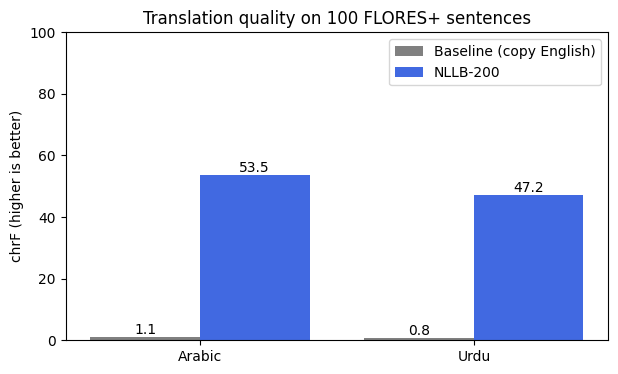

In [8]:
import matplotlib.pyplot as plt

names = results_df["Language"].tolist()
baseline = results_df["Baseline chrF (copy English)"].tolist()
nllb = results_df["NLLB chrF"].tolist()
positions = list(range(len(names)))

plt.figure(figsize=(7, 4))
plt.bar([p - 0.2 for p in positions], baseline, width=0.4, label="Baseline (copy English)", color="gray")
plt.bar([p + 0.2 for p in positions], nllb, width=0.4, label="NLLB-200", color="royalblue")
for p in positions:
    plt.text(p - 0.2, baseline[p] + 1, str(baseline[p]), ha="center")
    plt.text(p + 0.2, nllb[p] + 1, str(nllb[p]), ha="center")
plt.xticks(positions, names)
plt.ylabel("chrF (higher is better)")
plt.ylim(0, 100)
plt.title("Translation quality on " + str(N_SENTENCES) + " FLORES+ sentences")
plt.legend()
plt.show()

In [9]:
sentence_scores = {}

for name in LANGS:
    code = LANGS[name]
    scores = []
    for i in range(len(english)):
        score = sacrebleu.sentence_chrf(translations[name][i], [sample[code][i]]).score
        scores.append(round(score, 1))
    sentence_scores[name] = scores

    table = pd.DataFrame({"English": english,
                          "NLLB output": translations[name],
                          "Professional translation": sample[code],
                          "chrF": scores})
    print("5 worst translations:", name)
    display(table.sort_values("chrF").head(5))

5 worst translations: Arabic


,English,NLLB output,Professional translation,chrF
84,"But, after losing the captain's wicket India o...",لكن بعد خسارة كابتن النزول الهند فقط 36 رنز فق...,لكن من بعد خسارة القائد للتسديد في البُويبة، ح...,24.7
30,Up means you should start at the tip and push ...,فوق يعني أن تبدأ من النقطة وتدفع القوس، والسفل...,تفيد علامة أعلى بوجوب البدء من الطرف ودفع القو...,28.1
85,"The main local beer is 'Number One', it is not...","البيرة المحلية الرئيسية هي ""الرقم واحد""، وهي ل...","تُعرف البيرة الشعبية الأساسية باسم ""رقم واحد""،...",28.7
36,It is Martelly's fifth CEP in four years.,إنه الخامس من مدير عمله في أربع سنوات,إنه المجلس الانتخابي المؤقت الخامس لمارتيلي خل...,29.1
82,"Middle order batsmen, Sachin Tendulkar and Rah...",قام الباتسمانون من الدرجة المتوسطة، سچن تندولك...,أدى ضاربا الكرة المتمركزين في الوسط، ساشين تين...,29.9


5 worst translations: Urdu


,English,NLLB output,Professional translation,chrF
55,"He referred to the rumors as ""political chatte...","انہوں نے افواہوں کو ""سیاسی گفتگو اور بیوقوفی"" ...",اس نے شایعات کو ”سیاسی گپ اور حماقت“ قرار دیا۔,19.4
7,Sleep interruption is the process of purposefu...,نیند کی رکاوٹ آپ کی معمول کی نیند کی مدت کے دو...,تمہارے نارمل نیند کے اوقات میں نیند کا ٹوٹنا ا...,26.2
24,"Periodic rhythms, which are not simply respons...",دورانیہ ریتم، جو صرف بیرونی دورانیہ اشارے کے ج...,ایسے متواتر تال جو محض کسی بیرونی متواتر اشارے...,28.7
73,Bishkek was described as sinking into a state ...,"ایک مبصر نے بیشکک کو ""غیر قانونی حالت"" میں ڈوب...",جب لٹیروں کی ٹولیاں سڑکوں پر گھوم رہی تھیں اور...,29.0
74,The idea of skiing is very old — cave painting...,اسکینگ کا خیال بہت پرانا ہے اسکیروں کی تصویر ...,اسکیئنگ (برف پر پھسلنے کا مشغلہ) بہت قدیم ہے —...,29.5


In [10]:
import re

def western_digits(text):
    arabic_digits = "٠١٢٣٤٥٦٧٨٩"
    urdu_digits = "۰۱۲۳۴۵۶۷۸۹"
    for i in range(10):
        text = text.replace(arabic_digits[i], str(i))
        text = text.replace(urdu_digits[i], str(i))
    return text

def get_numbers(text):
    text = western_digits(text)
    text = text.replace(",", "").replace("،", "").replace("٬", "")
    return re.findall(r"\d+", text)

def numbers_ok(english_text, translated_text):
    english_numbers = get_numbers(english_text)
    translated_numbers = get_numbers(translated_text)
    for number in english_numbers:
        if number in translated_numbers:
            translated_numbers.remove(number)
        else:
            return False
    return True

def number_accuracy(english_list, translated_list):
    total = 0
    correct = 0
    for i in range(len(english_list)):
        if len(get_numbers(english_list[i])) > 0:
            total = total + 1
            if numbers_ok(english_list[i], translated_list[i]):
                correct = correct + 1
    return round(100 * correct / total)

count = 0
for sentence in english:
    if len(get_numbers(sentence)) > 0:
        count = count + 1
print(count, "of", len(english), "sentences contain a number")

for name in LANGS:
    print(name, ":", number_accuracy(english, translations[name]), "% of number sentences kept all numbers")

27 of 100 sentences contain a number
Arabic : 81 % of number sentences kept all numbers
Urdu : 89 % of number sentences kept all numbers


In [11]:
for name in LANGS:
    code = LANGS[name]
    errors = []
    for i in range(len(english)):
        if len(get_numbers(english[i])) > 0 and not numbers_ok(english[i], translations[name][i]):
            errors.append([english[i], translations[name][i], sample[code][i]])
    print(name, ":", len(errors), "number errors")
    display(pd.DataFrame(errors, columns=["English", "NLLB output", "Professional translation"]))

Arabic : 5 number errors


,English,NLLB output,Professional translation
0,Sleep interruption is the process of purposefu...,انقطاع النوم هو عملية الاستيقاظ بشكل متعمد خلا...,انقطاع النوم هو عملية الاستيقاظ عن عمد خلال فت...
1,During the 1980s he worked on shows such as Ta...,خلال الثمانينيات عمل على برامج مثل تاكسي وشاير...,وخلال الثمانينيات من القرن الماضي، عمل في عروض...
2,Goats seem to have been first domesticated rou...,يبدو أن الماعزة تم تربيتها لأول مرة قبل حوالي ...,يبدو أن الماعز قد دُجّن للمرة الأولى منذ ما يق...
3,"Germany was a common enemy in World War 2, lea...",كانت ألمانيا عدوًا مشتركًا في الحرب العالمية ا...,مثلت ألمانيا عدواً مشتركاً في الحرب العالمية ا...
4,"Around 3 minutes into the launch, an on-board ...",بعد حوالي ثلاث دقائق من الإطلاق، أظهرت كاميرا ...,أظهرت كاميرا مثبتة على متن المكوك بعد حوالي 3 ...


Urdu : 3 number errors


,English,NLLB output,Professional translation
0,The Amazon River is the second longest and the...,ایمیزون دریا زمین کا دوسرا طویل ترین اور سب سے...,امیزن ندی دوسری سب سے لمبی اور زمین کی سب بڑی ...
1,Sleep interruption is the process of purposefu...,نیند کی رکاوٹ آپ کی معمول کی نیند کی مدت کے دو...,تمہارے نارمل نیند کے اوقات میں نیند کا ٹوٹنا ا...
2,"Germany was a common enemy in World War 2, lea...",دوسری جنگ عظیم میں جرمنی ایک مشترکہ دشمن تھا ج...,جنگِ عظیم 2 میں جرمنی ایک مُشترکہ دُشمن تھا، ج...


In [12]:
def repair_numbers(english_text, translated_text):
    if numbers_ok(english_text, translated_text):
        return translated_text
    english_parts = re.findall(r"\d+", english_text)
    text = western_digits(translated_text)
    translated_parts = re.findall(r"\d+", text)
    if len(english_parts) == 0 or len(english_parts) != len(translated_parts):
        return translated_text
    for i in range(len(translated_parts)):
        text = text.replace(translated_parts[i], "@" + chr(65 + i) + "@", 1)
    for i in range(len(english_parts)):
        text = text.replace("@" + chr(65 + i) + "@", english_parts[i], 1)
    return text

beam_translations = {}
repaired_translations = {}
fix_rows = []

for name in LANGS:
    code = LANGS[name]
    references = sample[code].tolist()
    beam_translations[name] = translate_list(english, code, beams=5)
    repaired = []
    for i in range(len(english)):
        repaired.append(repair_numbers(english[i], beam_translations[name][i]))
    repaired_translations[name] = repaired

    methods = [["1. Greedy", translations[name]],
               ["2. Beam search (5)", beam_translations[name]],
               ["3. Beam search + number repair", repaired_translations[name]]]
    for method in methods:
        score = sacrebleu.corpus_chrf(method[1], [references]).score
        fix_rows.append([name, method[0], round(score, 1), number_accuracy(english, method[1])])

fix_df = pd.DataFrame(fix_rows, columns=["Language", "Method", "chrF", "Numbers kept (%)"])
fix_df

,Language,Method,chrF,Numbers kept (%)
0,Arabic,1. Greedy,53.5,81
1,Arabic,2. Beam search (5),54.6,81
2,Arabic,3. Beam search + number repair,54.6,81
3,Urdu,1. Greedy,47.2,89
4,Urdu,2. Beam search (5),47.4,89
5,Urdu,3. Beam search + number repair,47.4,89


In [13]:
import numpy as np
from scipy.stats import spearmanr

back_translations = {}
back_scores = {}
thresholds = {}
warn_rows = []

for name in LANGS:
    code = LANGS[name]
    back_translations[name] = translate_list(translations[name], "eng_Latn", src_lang=code)
    scores = []
    for i in range(len(english)):
        scores.append(sacrebleu.sentence_chrf(back_translations[name][i], [english[i]]).score)
    back_scores[name] = scores

    rho, p = spearmanr(back_scores[name], sentence_scores[name])

    thresholds[name] = np.percentile(back_scores[name], 25)
    bad_cutoff = np.percentile(sentence_scores[name], 25)
    really_bad = 0
    caught = 0
    for i in range(len(english)):
        if sentence_scores[name][i] <= bad_cutoff:
            really_bad = really_bad + 1
            if back_scores[name][i] <= thresholds[name]:
                caught = caught + 1

    warn_rows.append([name, round(rho, 2), round(p, 4), round(thresholds[name], 1),
                      str(caught) + "/" + str(really_bad),
                      "about " + str(round(really_bad * 0.25)) + "/" + str(really_bad)])

warn_df = pd.DataFrame(warn_rows, columns=["Language", "Spearman correlation", "p-value",
                                           "Warning threshold", "Worst 25% caught",
                                           "Random guessing would catch"])
warn_df

,Language,Spearman correlation,p-value,Warning threshold,Worst 25% caught,Random guessing would catch
0,Arabic,0.34,0.0005,54.3,9/25,about 6/25
1,Urdu,0.21,0.0344,57.1,8/25,about 6/25


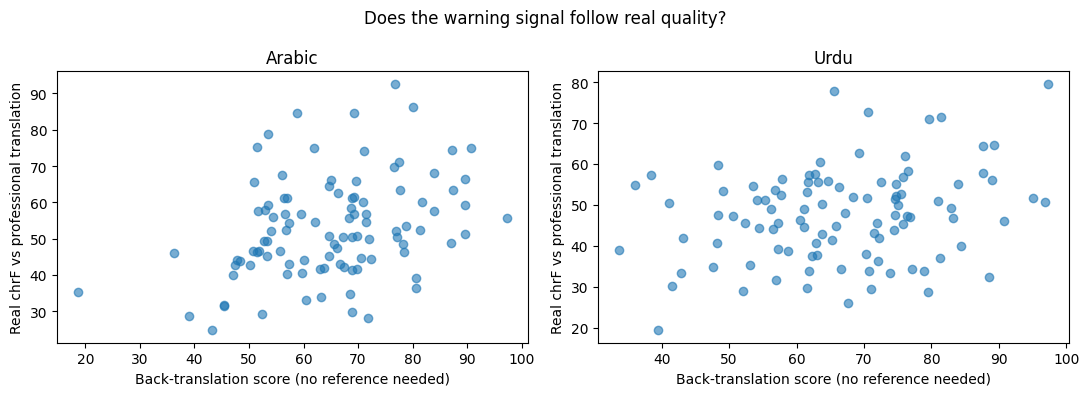

In [14]:
plt.figure(figsize=(11, 4))
number = 1
for name in LANGS:
    plt.subplot(1, 2, number)
    plt.scatter(back_scores[name], sentence_scores[name], alpha=0.6)
    plt.xlabel("Back-translation score (no reference needed)")
    plt.ylabel("Real chrF vs professional translation")
    plt.title(name)
    number = number + 1
plt.suptitle("Does the warning signal follow real quality?")
plt.tight_layout()
plt.show()

In [15]:
SCHOOL_NOTICES = [
    "School will be closed on Monday, 18 November, for a public holiday.",
    "Parent-teacher meetings will take place on Thursday from 3:30 pm to 6:00 pm.",
    "Please pay the 25 dollar trip fee by Friday.",
    "Your child must bring a packed lunch and a water bottle tomorrow.",
    "If your child has a fever, please keep them at home and call the school office.",
    "The school bus will leave at 7:15 am instead of 7:45 am next week.",
    "Exams start on 2 December. Students should arrive 20 minutes early.",
    "Please sign the permission form and return it to the class teacher.",
    "Children with nut allergies must not eat food from other students.",
    "Pick-up time on Wednesday is 12:30 pm because of teacher training.",
]

def too_long(english_text, translated_text):
    return len(translated_text.split()) > 2 * len(english_text.split()) + 5

def check_translation(english_text, translated_text, back_text, name):
    problems = []
    if not numbers_ok(english_text, translated_text):
        problems.append("number changed")
    if too_long(english_text, translated_text):
        problems.append("too long or repeating")
    score = sacrebleu.sentence_chrf(back_text, [english_text]).score
    if score <= thresholds[name]:
        problems.append("meaning may be lost")
    if len(problems) == 0:
        return "OK", score
    return "CHECK WITH A HUMAN: " + ", ".join(problems), score

notice_rows = []
for name in LANGS:
    code = LANGS[name]
    for notice in SCHOOL_NOTICES:
        translated = translate_one(notice, code, beams=5)
        translated = repair_numbers(notice, translated)
        back = translate_one(translated, "eng_Latn", src_lang=code)
        verdict, score = check_translation(notice, translated, back, name)
        notice_rows.append([name, notice, translated, back, verdict])

notices_df = pd.DataFrame(notice_rows, columns=["Language", "English notice", "Translation",
                                                "Back to English", "Verdict"])
pd.set_option("display.max_colwidth", 200)
notices_df

,Language,English notice,Translation,Back to English,Verdict
0,Arabic,"School will be closed on Monday, 18 November, for a public holiday.",ستغلق المدرسة يوم الاثنين، 18 نوفمبر، بسبب عطلة عامة.,"The school will be closed on Monday, November 18, because of a public holiday.",OK
1,Arabic,Parent-teacher meetings will take place on Thursday from 3:30 pm to 6:00 pm.,ستعقد اجتماعات الوالدين والمعلمين يوم الخميس من الساعة 3:30 مساءً إلى الساعة 6:00 مساءً.,Parent and teacher meetings will be held on Thursdays from 3.30pm to 6.00pm.,OK
2,Arabic,Please pay the 25 dollar trip fee by Friday.,من فضلك ادفع رسوم الرحلة البالغة 25 دولار بحلول يوم الجمعة,Please pay the $25 fare by Friday.,OK
3,Arabic,Your child must bring a packed lunch and a water bottle tomorrow.,يجب على طفلك أن يحضر غداءً و زجاجة ماء غداً,Your baby has to bring lunch and a bottle of water tomorrow.,CHECK WITH A HUMAN: meaning may be lost
4,Arabic,"If your child has a fever, please keep them at home and call the school office.",إذا كان طفلك يعاني من الحمى، من فضلك أبقيه في المنزل واتصل بمكتب المدرسة.,"If your child has a fever, please keep him at home and call the school office.",OK
5,Arabic,The school bus will leave at 7:15 am instead of 7:45 am next week.,ستغادر الحافلة المدرسية في الساعة السابعة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والأسبوع المقبل,"The school bus will leave at 7:00, 5:00, 5:00, 5:00, 5:00, 5:00, 5:00, 5:00, and next week.",CHECK WITH A HUMAN: number changed
6,Arabic,Exams start on 2 December. Students should arrive 20 minutes early.,الامتحانات تبدأ في 2 ديسمبر يجب أن يصل الطلاب قبل 20 دقيقة,The exams start on December 2nd. Students must arrive 20 minutes early.,OK
7,Arabic,Please sign the permission form and return it to the class teacher.,يرجى التوقيع على نموذج الإذن وإعادته إلى معلم الفصل.,Please sign the permit form and return it to the class teacher.,OK
8,Arabic,Children with nut allergies must not eat food from other students.,لا يجوز للأطفال الذين يعانون من حساسية النعناع تناول الطعام من الطلاب الآخرين.,Children with mint allergy may not eat from other students.,OK
9,Arabic,Pick-up time on Wednesday is 12:30 pm because of teacher training.,وقت الوصول يوم الأربعاء هو 12:30 بعد الظهر بسبب تدريب المعلمين.,Arrival time on Wednesday is 12:30 pm because of teacher training.,OK


In [20]:
HUMAN_ARABIC = ["Yes", "Yes", "Yes", "No", "Yes", "No", "Yes", "Yes", "No", "No"]
HUMAN_URDU   = ["Yes", "Yes", "Yes", "Yes", "Yes", "Yes", "Yes", "Yes", "Yes", "No"]

NOTES = [
    "",
]

human_answers = HUMAN_ARABIC + HUMAN_URDU
notices_df["Parent understands? (human)"] = human_answers

if "?" in human_answers:
    print("Replace every ? with Yes or No first.")
else:
    for name in LANGS:
        rows = notices_df[notices_df["Language"] == name]
        safe = 0
        for answer in rows["Parent understands? (human)"]:
            if answer == "Yes":
                safe = safe + 1
        print(name, ":", safe, "of", len(rows), "notices a parent would understand correctly")

    caught = 0
    missed = 0
    false_alarms = 0
    for i in range(len(notices_df)):
        flagged = notices_df["Verdict"][i] != "OK"
        human_no = notices_df["Parent understands? (human)"][i] == "No"
        if human_no and flagged:
            caught = caught + 1
        if human_no and not flagged:
            missed = missed + 1
        if flagged and not human_no:
            false_alarms = false_alarms + 1
    print()
    print("Bad translations our checks caught:", caught)
    print("Bad translations our checks missed:", missed)
    print("False alarms (flagged but actually fine):", false_alarms)
    print()
    for note in NOTES:
        print(note)
    display(notices_df[["Language", "English notice", "Translation", "Verdict", "Parent understands? (human)"]])

Arabic : 8 of 10 notices a parent would understand correctly
Urdu : 9 of 10 notices a parent would understand correctly

Bad translations our checks caught: 3
Bad translations our checks missed: 0
False alarms (flagged but actually fine): 0




,Language,English notice,Translation,Verdict,Parent understands? (human)
0,Arabic,"School will be closed on Monday, 18 November, for a public holiday.",ستغلق المدرسة يوم الاثنين، 18 نوفمبر، بسبب عطلة عامة.,OK,Yes
1,Arabic,Parent-teacher meetings will take place on Thursday from 3:30 pm to 6:00 pm.,ستعقد اجتماعات الوالدين والمعلمين يوم الخميس من الساعة 3:30 مساءً إلى الساعة 6:00 مساءً.,OK,Yes
2,Arabic,Please pay the 25 dollar trip fee by Friday.,من فضلك ادفع رسوم الرحلة البالغة 25 دولار بحلول يوم الجمعة,OK,Yes
3,Arabic,Your child must bring a packed lunch and a water bottle tomorrow.,يجب على طفلك أن يحضر غداءً و زجاجة ماء غداً,CHECK WITH A HUMAN: meaning may be lost,No
4,Arabic,"If your child has a fever, please keep them at home and call the school office.",إذا كان طفلك يعاني من الحمى، من فضلك أبقيه في المنزل واتصل بمكتب المدرسة.,OK,Yes
5,Arabic,The school bus will leave at 7:15 am instead of 7:45 am next week.,ستغادر الحافلة المدرسية في الساعة السابعة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والخامسة والأسبوع المقبل,CHECK WITH A HUMAN: number changed,No
6,Arabic,Exams start on 2 December. Students should arrive 20 minutes early.,الامتحانات تبدأ في 2 ديسمبر يجب أن يصل الطلاب قبل 20 دقيقة,OK,Yes
7,Arabic,Please sign the permission form and return it to the class teacher.,يرجى التوقيع على نموذج الإذن وإعادته إلى معلم الفصل.,OK,Yes
8,Arabic,Children with nut allergies must not eat food from other students.,لا يجوز للأطفال الذين يعانون من حساسية النعناع تناول الطعام من الطلاب الآخرين.,OK,Yes
9,Arabic,Pick-up time on Wednesday is 12:30 pm because of teacher training.,وقت الوصول يوم الأربعاء هو 12:30 بعد الظهر بسبب تدريب المعلمين.,OK,Yes


In [16]:
for i in range(20):
    print("[" + str(i + 1) + "] EN:", english[i])
    print("     " + LOW_NAME + ":", translations[LOW_NAME][i])
    print()

[1] EN: Vatican City's population is around 800. It is the smallest independent country in the world and the country with the lowest population.
     Urdu: ویٹیکن سٹی کی آبادی 800 کے قریب ہے۔ یہ دنیا کا سب سے چھوٹا آزاد ملک اور آبادی کا سب سے کم ملک ہے۔

[2] EN: All citizens of Vatican City are Roman Catholic.
     Urdu: ویٹیکن سٹی کے تمام شہری رومن کیتھولک ہیں۔

[3] EN: It has a notably wide variety of plant communities, due to its range of microclimates, differing soils and varying levels of altitude.
     Urdu: اس میں خاص طور پر پودوں کی وسیع اقسام کی کمیونٹیز ہیں، کیونکہ اس کی مائکرو آب و ہوا کی حد، مختلف مٹی اور مختلف بلندیوں کی سطح.

[4] EN: The Amazon River is the second longest and the biggest river on Earth. It carries more than 8 times as much water as the second biggest river.
     Urdu: ایمیزون دریا زمین کا دوسرا طویل ترین اور سب سے بڑا دریا ہے۔ اس میں دوسری بڑی دریا سے آٹھ گنا زیادہ پانی بہتا ہے۔

[5] EN: Lion prides act much like packs of wolves or dogs, animals surprisin

In [17]:
MY_RATINGS = [4, 5, 4, 5, 3, 5, 5, 3, 5, 5,
              5, 5, 5, 5, 5, 5, 5, 5, 4, 5]

chrf_20 = sentence_scores[LOW_NAME][:20]
back_20 = back_scores[LOW_NAME][:20]

rho1, p1 = spearmanr(MY_RATINGS, chrf_20)
rho2, p2 = spearmanr(MY_RATINGS, back_20)
print("Rated sentences:", len(MY_RATINGS))
print("Average human score:", round(np.mean(MY_RATINGS), 2), "/ 5")
print("Average chrF of the same sentences:", round(np.mean(chrf_20), 1), "/ 100")
print("Human vs chrF: Spearman =", round(rho1, 2), " p =", round(p1, 3))
print("Human vs back-translation warning: Spearman =", round(rho2, 2), " p =", round(p2, 3))

Rated sentences: 20
Average human score: 4.65 / 5
Average chrF of the same sentences: 49.0 / 100
Human vs chrF: Spearman = 0.11  p = 0.638
Human vs back-translation warning: Spearman = 0.44  p = 0.055


In [18]:
import gradio as gr

def demo(text, language):
    text = text.strip()
    if text == "":
        return "", "", ""
    code = LANGS[language]
    translated = translate_one(text, code, beams=5)
    translated = repair_numbers(text, translated)
    back = translate_one(translated, "eng_Latn", src_lang=code)
    verdict, score = check_translation(text, translated, back, language)
    return translated, back, verdict + "  (back-translation score " + str(round(score)) + ")"

app = gr.Interface(
    fn=demo,
    inputs=[gr.Textbox(label="English notice", lines=3, value="Please pay the 25 dollar trip fee by Friday."),
            gr.Dropdown(list(LANGS.keys()), value=LOW_NAME, label="Translate into")],
    outputs=[gr.Textbox(label="Translation"),
             gr.Textbox(label="Back to English"),
             gr.Textbox(label="Can you trust it?")],
    title="METranslate",
    description="Translate school notices for parents and see when a human should check the translation.",
)
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://714137cbc30e6715ac.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
print("RESULTS SUMMARY")
print()
print("Baseline vs NLLB (chrF on", N_SENTENCES, "FLORES+ devtest sentences):")
print(results_df.to_string(index=False))
print()
print("Number errors and fixes:")
print(fix_df.to_string(index=False))
print()
print("Back-translation warning:")
print(warn_df.to_string(index=False))
print()
gap = nllb[0] - nllb[1]
print("Gap between", HIGH_NAME, "and", LOW_NAME, ":", round(gap, 1), "chrF points")

RESULTS SUMMARY

Baseline vs NLLB (chrF on 100 FLORES+ devtest sentences):
Language  Baseline chrF (copy English)  NLLB chrF  Seconds
  Arabic                           1.1       53.5       86
    Urdu                           0.8       47.2       65

Number errors and fixes:
Language                         Method  chrF  Numbers kept (%)
  Arabic                      1. Greedy  53.5                81
  Arabic             2. Beam search (5)  54.6                81
  Arabic 3. Beam search + number repair  54.6                81
    Urdu                      1. Greedy  47.2                89
    Urdu             2. Beam search (5)  47.4                89
    Urdu 3. Beam search + number repair  47.4                89

Back-translation warning:
Language  Spearman correlation  p-value  Warning threshold Worst 25% caught Random guessing would catch
  Arabic                  0.34   0.0005               54.3             9/25                  about 6/25
    Urdu                  0.21   0.0344